# Naive Bayes

One of the two baseline models from the paper (Section IV-A, originally from Kachavimath et al. [4]).

Gaussian Naive Bayes models each feature as a bell curve per class (normal vs DoS) and multiplies the per-feature probabilities together. That product assumes the features are **independent** given the class, which is the "naive" part. Training is just computing means and variances, so it is very fast. Defined in `src/dosdetect/models.py` as `naive_bayes()`.

In [1]:
import pandas as pd

from dosdetect.data import prepare_all
from dosdetect.evaluate import evaluate_all, metrics_table, paper_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

NSL-KDD, normal and DoS traffic only (`dosdetect.data.prepare_all`). Four setups:

- **official**: train on `KDDTrain+`, test on `KDDTest+`. About 23% of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm).
- **holdout**: stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **8 features** (top 8 by |correlation| with the label, our reading of the paper's filter) or **all 41**. These are not exactly the paper's 8: it names `dst_bytes` and `protocol_type` among its features, and neither is in our top 8 (see the README).

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print("Unseen DoS rows in official test:", official["unseen"].sum())
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717


,|correlation| with label
same_srv_rate,0.8654
dst_host_srv_serror_rate,0.7913
dst_host_serror_rate,0.7855
srv_serror_rate,0.7853
serror_rate,0.7850
dst_host_same_srv_rate,0.7600
flag,0.7567
dst_host_srv_count,0.7189


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results = evaluate_all(MODELS["naive_bayes"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8674,0.9674,0.7191,0.8250,0.8108,0.4123,0.0140,0.0012
"official, 41 features",0.6178,0.5395,0.8206,0.6510,0.9336,0.4426,0.1031,0.0028
"holdout, 8 features",0.9356,0.9436,0.8947,0.9185,NaN,NaN,0.0113,0.0012
"holdout, 41 features",0.6578,0.5434,0.9763,0.6982,NaN,NaN,0.0311,0.0030


### Compared with the paper

The paper reports one result per model, taken from [4] and measured across KDDCup **and** NSL-KDD, with an unstated split and a different 8-feature set. So this is a rough reference point, not a like-for-like comparison. It sits much closer to our easier holdout split than to the official test file.

In [4]:
paper_table("naive_bayes", results)

official, 8 features                      holdout, 8 features  \
                          ours paper [4] difference                ours   
accuracy                0.8674    0.9395    -0.0721              0.9356   
precision               0.9674    0.9774    -0.0100              0.9436   
recall                  0.7191    0.9554    -0.2363              0.8947   

                                
          paper [4] difference  
accuracy     0.9395    -0.0039  
precision    0.9774    -0.0338  
recall       0.9554    -0.0607

### Confusion matrices

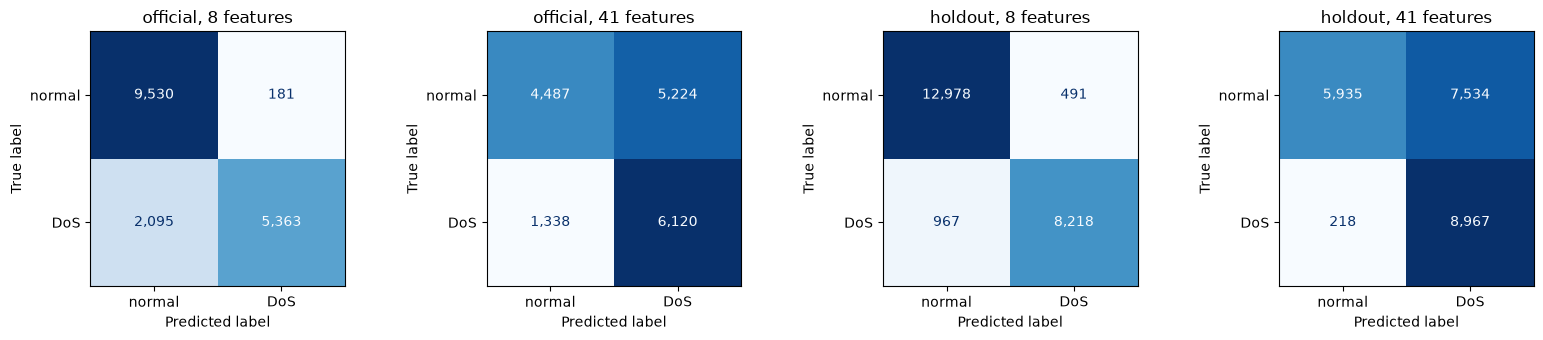

In [5]:
plot_confusions(results);

## Why more features can hurt Naive Bayes

Many NSL-KDD features are near-copies of each other (e.g. `serror_rate` and `srv_serror_rate`). Naive Bayes counts each copy as separate evidence, so duplicated features get over-weighted. The table counts feature pairs with |correlation| > 0.9 in the training data.

In [6]:
import numpy as np


def strongly_correlated_pairs(X, threshold=0.9):
    corr = X.corr().abs().to_numpy()
    return int(((corr > threshold) & np.triu(np.ones_like(corr, dtype=bool), k=1)).sum())


pd.DataFrame(
    {
        "pairs with |r| > 0.9": [
            strongly_correlated_pairs(data[("official", n)]["X_train"]) for n in (8, 41)
        ],
        "accuracy (official)": [results[("official", n)]["accuracy"] for n in (8, 41)],
        "precision (official)": [results[("official", n)]["precision"] for n in (8, 41)],
    },
    index=pd.Index([8, 41], name="features"),
)

,pairs with |r| > 0.9,accuracy (official),precision (official)
features,,,
8,7,0.8674,0.9674
41,14,0.6178,0.5395


## Takeaways

- **Closest to the paper's reported numbers.** On the holdout split with 8 features, accuracy is 93.6% against the paper's 93.95%. On the official test file it is 86.7%.
- **Best at catching unseen attacks**: 41–44% recall on never-seen DoS types, versus 7–33% for the other models. Its rough bell-curve picture of each class generalises further than the other models' tight fit to the training data.
- **Breaks down with all 41 features.** Accuracy falls to 62% and precision to 54%, so nearly half of its DoS alarms are normal traffic. The 41-feature set has twice as many near-duplicate feature pairs, and the independence assumption counts each copy as extra evidence. Correlation-based feature selection matters most for this model.
- **Fastest model**: trains in about 0.01–0.04 s and predicts in milliseconds.